# Data quality and transaction audit

Source: Chen (2012), Online Retail II, UCI, CC BY 4.0. Run the pipeline before this notebook. Figures describe historical purchases, not loyalty membership or causal offer effects.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'configs').exists() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')


In [2]:
audit=json.loads((ROOT/'reports/data_audit.json').read_text())
pd.Series(audit).to_frame('value')

,value
raw_rows,1067371
exact_duplicates,34335
missing_customer_or_date,235151
cancellations_nonpositive,18460
administrative_lines,2848
partial_final_day,605
clean_rows,775972
customers,5851
invoices,36553
observation_end_exclusive,2011-12-09


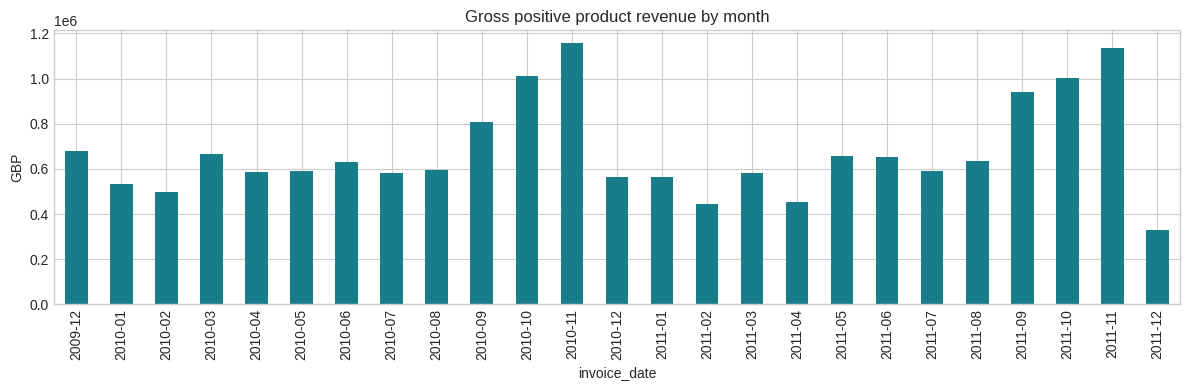

In [3]:
tx=pd.read_parquet(ROOT/'data/processed/transactions.parquet')
monthly=tx.groupby(tx.invoice_date.dt.to_period('M')).revenue.sum()
ax=monthly.plot(kind='bar',figsize=(12,4),color='#177e89',title='Gross positive product revenue by month')
ax.set_ylabel('GBP');plt.tight_layout();plt.show()

In [4]:
orders=tx.groupby(['customer_id','invoice']).invoice_date.min().reset_index().sort_values(['customer_id','invoice_date'])
gaps=orders.groupby('customer_id').invoice_date.diff().dt.total_seconds().div(86400).dropna()
gaps.quantile([.25,.5,.75,.9,.95]).to_frame('Interpurchase gap, days')

,"Interpurchase gap, days"
0.25,7.026389
0.50,25.043403
0.75,62.114410
0.90,136.013819
0.95,207.038090


## Interpretation
Compare against the baseline and report limitations. No purchase for 90 days does not prove permanent churn. Large wholesale purchases can dominate spending error. Survival diagnostics can reject proportional hazards; the Cox model is exploratory if that assumption fails. Retention priority is a heuristic requiring an experiment before claiming campaign benefit.